<a href="https://colab.research.google.com/github/JosueVele77/perceptron-learning-visualization/blob/main/Practica_03_Perceptron.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**📌Practica 3** *- El perceptrón*
---
*Universidad Politecnica Salesiana* \
*Josue Vele* \
*Inteligencia Artificial* \
*13 de Noviembre del 2026*


In [19]:
import random
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)

#**📖Fase 1** *- Exploración del Dataset*
*El perceptrón trabaja con datos numéricos. En este caso, cada instancia tiene dos variables de entrada: X1,
X2 y una etiqueta de salida: y { −1, 1 }*


---



##1.1 Carga del Dataset
*Crear una matriz denominada X y un vector y con los siguientes datos:*


In [ ]:
X =[
     [1, 7],[1, 3],[3, 4],[4, 6],[4, 2],[6, 6],[6, 2],[6, 0],
     [7, 4],[9, 3],[9, 1],[11, 1],[12, 30],[16, 2], [4, 8],
     [6, 8],[8, 9],[9, 7],[10, 11],[12, 9],[12, 6],[14, 7],[16, 4]
]
y = [-1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
     1, 1, 1, 1, 1, 1, 1, 1 ,1]

##**Actividad 1.a** *— Inspección inicial*
Identifica los siguientes datos:
* Número total de instancias
* Variables de entrada
* Número de clases
* Cantidad de puntos por clase


In [ ]:
n_instancias = 0
for _ in X:
  n_instancias += 1

n_variables = len(X[0])

clases = []
conteo = {}
for etiqueta in y:
  if etiqueta not in clases:
    clases.append(etiqueta)
    conteo[etiqueta] = 0
  conteo[etiqueta] += 1

print("Numero total de instancias:", n_instancias)
print("Variables de entrada:", n_variables, "-> x1, x2")
print("Numero de clases:", len(clases), "->", clases)
for c in clases:
    print(f" Cantidad de puntos por clase {c:+d}: {conteo[c]}")

Numero total de instancias: 23
Variables de entrada: 2 -> x1, x2
Numero de clases: 2 -> [-1, 1]
 Cantidad de puntos por clase -1: 14
 Cantidad de puntos por clase +1: 9


**💬Pregunta guía:**
* __*¿Qué representa cada fila de X?*__

*Cada fila de x es una instancia descrita por sus dos características de entrada [x1,x2].*

* __*¿Qué representa cada valor del vector y?*__

*Cada valor de y es la etiqueta real de la instancia que está en la misma posición de x: y[i] es la clase de x[i].*
* __*¿Por qué este problema se considera de clasificación binaria?*__

*Es clasificación binaria porque la salida solo puede tomar dos valores posibles, -1 o +1. El modelo debe decidir a cúal de esas dos categorías pertenece cada punto.*


##**Actividad 1.b** *— Separación visual de las clases*
*Crea una función que permita grafica los puntos en un plano cartesiano. Utiliza un marcador diferente para
la clase -1 y para la clase 1. Puedes utilizar matplotlib para esta actividad. La gráfica debería mirarse
similar a la siguiente figura.*


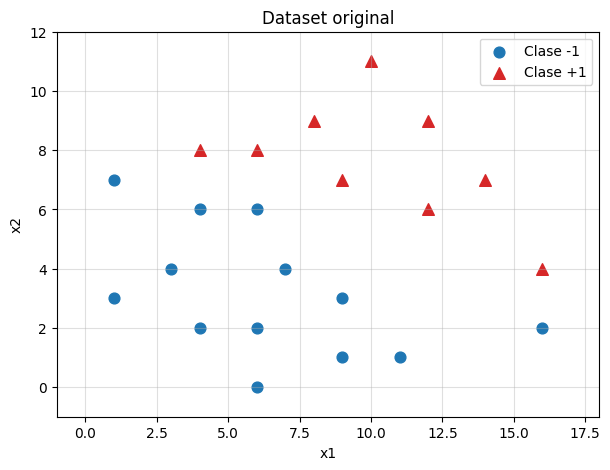

In [ ]:
def plot_dataset(X, y, title="Dataset"):
    neg_x1, neg_x2, pos_x1, pos_x2 = [], [], [], []
    for xi, yi in zip(X, y):
        if yi == -1:
            neg_x1.append(xi[0]); neg_x2.append(xi[1])
        else:
            pos_x1.append(xi[0]); pos_x2.append(xi[1])
    plt.figure(figsize=(7, 5))
    plt.scatter(neg_x1, neg_x2, marker="o", color="tab:blue", s=60, label="Clase -1")
    plt.scatter(pos_x1, pos_x2, marker="^", color="tab:red", s=70, label="Clase +1")
    plt.xlabel("x1"); plt.ylabel("x2"); plt.title(title)
    plt.xlim(-1, 18); plt.ylim(-1, 12)
    plt.grid(True, alpha=0.4); plt.legend()
    plt.show()

plot_dataset(X, y, "Dataset original")

**💬Pregunta guía:**
* *Observando únicamente la gráfica, ¿parece posible separar las dos clases mediante una sola recta? Justifica tu respuesta.*

*Sí, los puntos de la clase -1 se concentran en la parte inferior del plano y los de la clase +1 en la parte superior. Se puede trazar una recta ligeramente descendente que deja todos los +1 por debajo y todos los +1 por encima, sin que ningún punto quede del lado equivocado. La zona crítica es la esquina derecha, donde (16,2) es -1 y (16,4) es +1 están cerca, pero aun así una recta puede pasar entre ellos. Por eso el conjunto parece linealmente separable, condición bajo la cual el perceptrón garantiza convergencia.*

#**📖Fase 2** *- Fundamento del Perceptrón*
*$$z = w_0 + w_1x_1 + w_2x_2 \qquad \hat{y} = \begin{cases} 1 & z \ge 0 \\ -1 & z < 0 \end{cases}$$*

---



##**Actividad 2.a** *— Vector de pesos*
*Crea una función llamada initialize_weights() que retorne tres pesos aleatorios pequeños. Los pesos deben generarse en un rango pequeño, por ejemplo entre -0.5 y 0.5.*



In [ ]:
def initialize_weights(low = 0.5, high = 0.5):
  return [random.uniform(low, high) for _ in range(3)]

**💬Pregunta guía:**
* ¿Por qué el vector de pesos tiene tres valores si cada instancia de entrada solo tiene dos variables? ¿Qué función cumple el bias en el modelo?

*Hay un peso por cada entrada(w1 para x1 y w2 para x2) más el bias w0. El bias equivale a un peso conectado a una entrada ficticia que vale siempre 1.* \
*Sin bias, la frontera sería w1·x1 + w2·x2 = 0, una recta que siempre pasa por el origen. El bias permite desplazar la recta para que pueda ubicarse en cualquier lugar del plano; en otras palabras, actúa como un umbral ajustable que decide a partir de qué valor de la suma pondera la neurona. En este dataset es indispensable la frontera correcta corta al eje x2 cerca de 8, no es 0.*

##**Actividad 2.b** *— Función de activación*
Crea una función llamada activation(z) que reciba el valor de la suma ponderada y retorne el resultado de la función escalón bipolar:


In [ ]:
def activation(z):
  if z >= 0:
    return 1
  return -1

print(activation(2.5), activation(0), activation(-0.1))

1 1 -1


**💬Pregunta guía:**
* *¿Por qué en esta práctica se utilizan las etiquetas -1 y 1 en lugar de 0 y 1?* \

*Con etiquetas bipolares  el término de error (y − ŷ) solo puede valer 0,+2 o -2 y su signo indica directamente hacia dónde corregir:*
1. *Si el modelo predijo −1 pero era +1 → (y−ŷ) = +2 → los pesos se mueven hacia x esto hace que aumente z.*
2. *Si predijo +1 pero era −1 → (y−ŷ) = −2 → los pesos se alejan de x esto hace que disminuya z.*
* *¿Qué ventaja tiene esta representación para el algoritmo del perceptrón?*

*La representación es simétrica respecto a cero, que es justo el umbral de la función escalón, asi que ambas clases reciben correcciones de igual magnitud. \
Además permite escribir la condición de acierto de forma compacta, la instancia está bien clasificada si y·z > 0. Con 0/1, una estrada cuyo valor sea 0 no aporta nada a la corrección y la formulación es menos simétrica.*





##**Actividad 2.c** *— Cálculo de salida*
*Crea una función llamada perceptron_compute(x, w). La función debe recibir una sola instancia x = [x1, x2] y el vector de pesos w = [w0, w1, w2]. Esta función debe calcular la suma ponderada z y retornar la salida producida por la función de activación.*


In [ ]:
def perceptron_compute(x, w):
    if isinstance(x[0], (list, tuple)):
        return [perceptron_compute(xi, w) for xi in x]
    z = w[0] + w[1] * x[0] + w[2] * x[1]
    return activation(z)

**Hacemos una prueba manual con tres datos del dataset**

In [ ]:
w_prueba = [-8.0, 0.4, 1.0]
for idx in [0, 4, 15]:
    xi = X[idx]
    z = w_prueba[0] + w_prueba[1] * xi[0] + w_prueba[2] * xi[1]
    print(f"x = {xi}  z = {w_prueba[0]} + {w_prueba[1]}·{xi[0]} + {w_prueba[2]}·{xi[1]} = {z:6.2f}"
          f"  ->  ŷ = {perceptron_compute(xi, w_prueba):+d}   (y real = {y[idx]:+d})")



x = [1, 7]  z = -8.0 + 0.4·1 + 1.0·7 =  -0.60  ->  ŷ = -1   (y real = -1)
x = [4, 2]  z = -8.0 + 0.4·4 + 1.0·2 =  -4.40  ->  ŷ = -1   (y real = -1)
x = [6, 8]  z = -8.0 + 0.4·6 + 1.0·8 =   2.40  ->  ŷ = +1   (y real = +1)


**💬Pregunta guía:**
* *¿Cuál es la diferencia entre la suma ponderada z y la salida final del perceptrón?*
1. *z es un número real contínuo este puede ser -13.2,0.4 entre otros. Mide de qué lado de la recta está el punto y, en valor absoluto, qué tan lejos se encuentra de ella.*
2. *ŷ es la decisión esta aplica el umbral sobre z y devuelve una clase, -1 o +1.*
* *¿Por qué no basta con calcular solo z?*

*No basta con z porque el problema pide una etiqueta de clase, no un número, \
Ademas , la regla de aprendizaje compara y con ŷ para eso necesitamos saber si el modelo acretó o no, y eso solo se puede evaluar sobre la salida discreta. El signo de z contiene la decisión, pero la función de activación es la que la convierte explicitamente en una clase.*



#**📖Fase 3** *- Visualización de la Frontera de Decisión*

$$w_0 + w_1x_1 + w_2x_2 = 0 \;\Rightarrow\; x_2 = -\frac{w_1}{w_2}x_1 - \frac{w_0}{w_2}\quad (w_2 \ne 0)$$

---




##**Actividad 3.a** *— Función de graficación*

*Crea una función llamada perceptron_plot(X, y, w, title). La función debe:*
* *Graficar los puntos de la clase -1.*
* *Graficar los puntos de la clase 1.*
* *Graficar la frontera de decisión correspondiente al vector de pesos w.*
* *Colocar título, etiquetas de ejes, leyenda y cuadrícula.* \
*Considera el siguiente caso especial:*
* *Si w2 ≠ 0, puedes despejar x2*
* *Si w2 = 0, la recta no puede despejarse de esa forma y debes evitar la división para cero.*

In [ ]:
X1_MIN, X1_MAX = -1, 18
X2_MIN, X2_MAX = -1, 12

def perceptron_plot(X, y, w, title, ax=None, show=True):
    created = ax is None
    if created:
        fig, ax = plt.subplots(figsize=(7, 5))

    neg = [xi for xi, yi in zip(X, y) if yi == -1]
    pos = [xi for xi, yi in zip(X, y) if yi == 1]
    ax.scatter([p[0] for p in neg], [p[1] for p in neg], marker="o", color="tab:blue", s=50, label="Clase -1")
    ax.scatter([p[0] for p in pos], [p[1] for p in pos], marker="^", color="tab:red", s=60, label="Clase +1")

    w0, w1, w2 = w
    if w2 != 0:
        xs = [X1_MIN, X1_MAX]
        ys = [-(w1 / w2) * x1 - (w0 / w2) for x1 in xs]
        ax.plot(xs, ys, "k-", linewidth=2, label="Frontera")
    elif w1 != 0:
        x_v = -w0 / w1
        ax.plot([x_v, x_v], [X2_MIN, X2_MAX], "k-", linewidth=2, label="Frontera (vertical)")
    else:
        ax.text(0.5, 0.95, "w1 = w2 = 0: no existe frontera", transform=ax.transAxes, ha="center")

    ax.set_xlim(X1_MIN, X1_MAX); ax.set_ylim(X2_MIN, X2_MAX)
    ax.set_xlabel("x1"); ax.set_ylabel("x2"); ax.set_title(title)
    ax.grid(True, alpha=0.4); ax.legend(loc="upper left", fontsize=8)
    if created and show:
        plt.show()
    return ax

**💬Pregunta guía:**
* ¿Qué representa geométricamente la recta generada por el perceptrón?

*La recta es el conjunto de puntos donde z = 0, el límmite donde el perceptrón cambia de decisión. Divide el plano en dos semiplanos es un z ≥ 0 esto predice +1 y el otro z < 0 este predice -1. EL vector (w1, w2) es perpendicular a la recta y apunta hacia la region +1; la pendiente es -w1/w2 y el corte con el eje x2 es -w0/w2.*
* ¿Qué ocurre si los pesos iniciales son aleatorios?

*Con pesos aleatorios la recta queda en una posición y orientación arbitrarias, sin relación con los datos, puede atravesar los puntos de ambas clases, quedar fuera de la zona de los datos o incluso tener las regiones invertidas. Es solo el punto de partida que el entrenamiento irá corrigiendo.*

##**Actividad 3.b** *— Gráfica con pesos iniciales*

*Inicializa pesos aleatorios pequeños y grafica la frontera inicial.*

Pesos iniciales: [0.5, 0.5, 0.5]


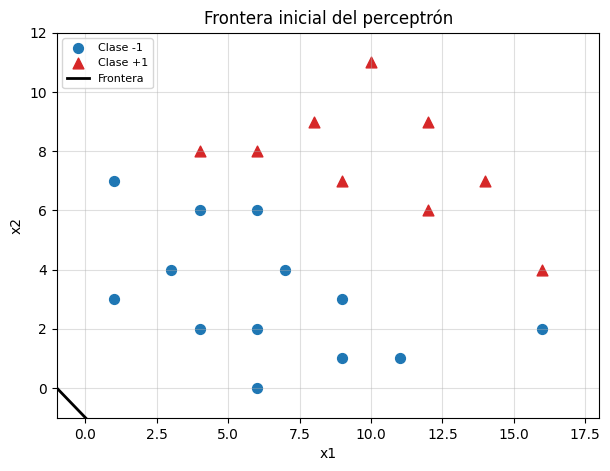

Instancias mal clasificadas con la frontera inicial: 14 de 23


In [ ]:
w_initial = initialize_weights()
print("Pesos iniciales:", [round(v, 4) for v in w_initial])
perceptron_plot(X, y, w_initial, "Frontera inicial del perceptrón")

errores_ini = sum(1 for xi, yi in zip(X, y) if perceptron_compute(xi, w_initial) != yi)
print(f"Instancias mal clasificadas con la frontera inicial: {errores_ini} de {len(X)}")

**💬Pregunta guía:**
* *¿La frontera inicial clasifica correctamente los puntos?*

*No, con la semilla usada la frontera inicial muy inclinada que pasa por la esquina inferior izquierda, fuera de la zona de datos.\
Como w2 < 0, la región +1 queda a la izquierda/abajo de la recta, donde no hay puntos; así los 23 puntos se clasifican como -1 y los 9 puntos de la clase +1 quedando mal clasificados. No se debe esperar que sea correcta porque los pesos se eligieron sin mirar los datos, no contiene ninguna información sobre el problema. Que una recta aleatoria separe justo estas dos clases sería pura casualidad, precisamente por eso se necesita el proceso de aprendizaje.*
* *¿Por qué no deberíamos esperar que una frontera con pesos aleatorios sea correcta?*

*La frontera de la recta w0 + w1·x1 + w2·x2 = 0. Todo punto donde la suma pondera es positiva o cero se asigna a +1 y el resto a -1. Cambiar w1 y w2 rota la recta esto significa que cambia su pendiente -w1/w2 y cambiar w0 la traslada a cambiar su corte -w0/w2.*

#**📖Fase 4** *- Entrenamiento del Perceptrón*

*$$w_i \leftarrow w_i + \eta(y-\hat{y})x_i \qquad w_0 \leftarrow w_0 + \eta(y-\hat{y}) \qquad E = \frac{\text{número de errores}}{\text{número total de instancias}}$$*


---



##**Actividad 4.a** *— Implementación de la función de aprendizaje*

*Crea una función llamada perceptron_learning(X, y, w, lr, max_epochs). La función debe recibir:*
* *Matriz de datos X*
* *Vector de etiquetas y*
* *Pesos iniciales w*
* *tasa de aprendizaje lr*
* *Número máximo de épocas max_epochs.*

*La función debe retornar:*
* *esos finales*
* *Número de épocas realizadas*
* *Número total de actualizaciones*
* *Lista con la evolución de pesos W_values;*
* *Lista con la evolución del error E_values.*

*La función debe entrenar hasta que:*
* *No exista ningún error de clasificación en una época o*
* *Se alcance el número máximo de épocas.*


**💬Pregunta guía:**
* *¿Por qué es necesario incluir un número máximo de épocas? ¿Qué podría ocurrir si el dataset no fuera linealmente separable?*

*El teorema de convergencia del perceptrón solo garantiza que el algoritmo termina si los datos son linealmente separables. Si no lo son, siempre habrá al menos un punto mal clasificado, cada corrección arregla un punto pero estropea otro, y los pesos oscilan indefinidamente. La condición "0 errores" nunca se cumpliría y el ciclo sería infinito. __`max_epochs`__ es un criterio de parada de seguridad que garantiza que la función termine; en ese caso se retornan los pesos de la última época.*


In [ ]:
def perceptron_learning(X, y, w, lr, max_epochs):
    w = list(w)                 # copia: no modificar el vector original
    W_values = [list(w)]        # estado inicial
    E_values = []
    total_updates = 0
    epochs = 0
    n = len(X)

    for epoch in range(1, max_epochs + 1):
        errors = 0
        for xi, yi in zip(X, y):
            y_hat = perceptron_compute(xi, w)
            if y_hat != yi:
                delta = lr * (yi - y_hat)
                w[0] += delta            # bias
                w[1] += delta * xi[0]
                w[2] += delta * xi[1]
                errors += 1
                total_updates += 1

        E_values.append(errors / n)      # 4.b: tasa de error de la época
        W_values.append(list(w))         # 4.c: COPIA de los pesos al final de la época
        epochs = epoch

        if errors == 0:                  # convergencia
            break

    return w, epochs, total_updates, W_values, E_values

##**Actividad 4.b** *— Registro del error*

*Durante cada época, calcula la tasa de error: \
Guarda ese valor en la lista E_values.*

**💬Pregunta guía:**
 * *¿Qué significa que la tasa de error llegue a cero?*

*Que es una época completa el perceptrón clasificó correctamente todas las instancias de entrenamiento y no tuvo que actualizar ningún peso. Es decir, el algortimo convergió, encontro una recta que separa perfectamente las dos clases del conjunto de entrenamiento, y a partir de ahí los pesos ya no cambiarían aunque se siguiera entrenando.*

##**Actividad 4.c** *— Registro de pesos*

*Después de cada época, guarda una copia del vector de pesos en W_values. Importante: no guardes la misma referencia del objeto w; guarda una copia de sus valores.*

**💬Pregunta guía:**
* ¿Por qué es importante guardar copias de los pesos y no solo el vector w?

*En python las listas son objetos mutables: __`W_values.append(w)`__ guarda una referencia al mismo objeto, no sus valores. Como w se modifica en el lugar (w[0]+=...), todas las entradas de __`W_values`__ apuntararían a la misma lista y al final mostrarían los pesos finales.*
* ¿Qué problema aparecería al intentar graficar la evolución del entrenamiento?

*Al graficar la evolución, las seis gráficas mostrarían la misma recta y parecería que el modelo nunca cambió. Con __`list(w)`__ se guarda una instantánea independiente de cada época. A continuación lo demostramos:*


In [ ]:
w_demo = [0.0, 0.0, 0.0]
por_referencia, por_copia = [], []
for k in range(3):
    w_demo[0] += 1
    por_referencia.append(w_demo)
    por_copia.append(list(w_demo))
print("Guardando la referencia:", por_referencia)
print("Guardando copias:       ", por_copia)

Guardando la referencia: [[3.0, 0.0, 0.0], [3.0, 0.0, 0.0], [3.0, 0.0, 0.0]]
Guardando copias:        [[1.0, 0.0, 0.0], [2.0, 0.0, 0.0], [3.0, 0.0, 0.0]]


#**📖Fase 5** *- Entrenamiento con tasa de aprendizaje 0.5*

*En esta fase entrenarás el perceptrón con:*
* *lr = 0.5*
* *max_epochs = 1000*

---



##**Actividad 5.a** *— Entrena el modelo*

*Inicializa pesos aleatorios y entrena el perceptrón. \
Muestra:*
* *Pesos iniciales*
* *Pesos finales*
* *Número de épocas*
* *Número total de actualizaciones*
* *Error final*


In [23]:
w = initialize_weights()

final_w, epochs, updates, W_values, E_values = perceptron_learning(
    X,
    y,
    w,
    lr=0.5,
    max_epochs=1000
)

print("Pesos iniciales:   ", [round(v, 4) for v in w])
print("Pesos finales:     ", [round(v, 4) for v in final_w])
print("Número de épocas:  ", epochs)
print("Actualizaciones:   ", updates)
print("Error final:       ", E_values[-1])
print("Primeros 10 errores por época:", [round(e, 3) for e in E_values[:10]])

Pesos iniciales:    [0.5, 0.5, 0.5]
Pesos finales:      [-53.5, 5.5, 4.5]
Número de épocas:   1000
Actualizaciones:    3524
Error final:        0.08695652173913043
Primeros 10 errores por época: [0.087, 0.13, 0.087, 0.13, 0.087, 0.13, 0.087, 0.13, 0.087, 0.13]


**💬Pregunta guía:**
* *¿El perceptrón logró converger?*

*__No__, Con esta configuración, el perceptrón no logró converger tras ejecutar las 1000 épocas y realizar 3524 actualizaciones.*

* ¿Cómo puedes comprobarlo usando la lista E_values y la gráfica final?

1. *En la lista __`E_values`__: El error final no es 0.0, sino aproximadamente 0.087, lo que indica que siguieron existiendo errores de clasificación en la última época. Además, el entrenamiento se detuvo exactamente en las 1000 épocas, demostrando que el ciclo terminó por agotar el límite de iteraciones y no porque el error llegara a cero. También se observa que el error oscila constantemente entre 0.087 y 0.13 sin estabilizarse.*

2. *En la gráfica final: La frontera de dicisión no logra separar completamente ambas clases. Visualmente, se observarán puntos mal clasificados, algunos triángulos rojos (+1) quedarán por debajo de la recta o algunos círculos azules (-1) quedarán por encima específicamente alrededor de un 8.7% de los datos.*


##**Actividad 5.b** *— Frontera final*

*Grafica la frontera de decisión final. perceptron_plot(X, y, final_w, "Frontera final con lr = 0.5")*

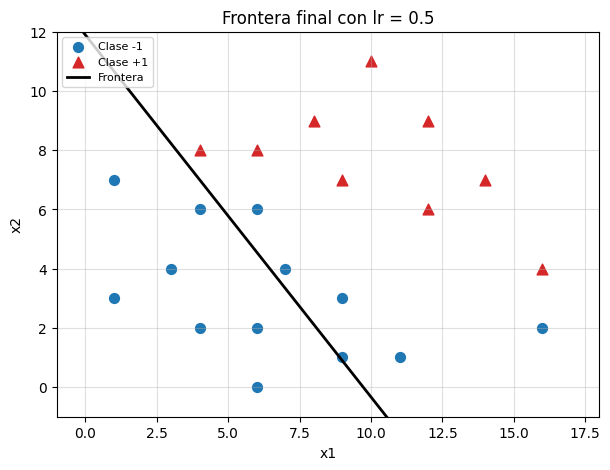

Recta final: x2 = -1.222·x1 + 11.889


In [24]:
perceptron_plot(X, y, final_w, "Frontera final con lr = 0.5")
print(f"Recta final: x2 = {-final_w[1]/final_w[2]:.3f}·x1 + {-final_w[0]/final_w[2]:.3f}")

**💬Pregunta guía:**
* *¿La frontera final separa correctamente las dos clases?*

*__No__, la frontera final no separa correctamente las dos clases. Aunque logra clasificar bien la mayoría de los puntos (21 de las 23 instancias), comete 2 errores que serian error final $\approx 0.087$, es decir, $2/23$, específicamente, deja los puntos de la clase -1 ubicados en (9, 3) y (16, 2) en la región superior correspondiente a la clase +1.*

* *¿Qué diferencias observas respecto a la frontera inicial?*

1. *Posición: La frontera inicial con pesos [0.5, 0.5, 0.5] ($x_2 = -1 \cdot x_1 - 1$) pasaba por fuera de la zona de los datos en la esquina inferior izquierda, clasificando todas las instancias en la región $+1$. La frontera final ($x_2 = -1.222 \cdot x_1 + 11.889$) se desplazó hacia arriba y a la derecha, cortando el eje $x_2$ cerca de 11.89, ubicándose entre ambas nubes de puntos pero sin lograr dejar todos los círculos azules por debajo.*

2. *Orientación: La recta inicial tenía una pendiente de $-1.0$, mientras que la final se volvió ligeramente más inclinada (pendiente $\approx -1.222$). Al caer de forma tan pronunciada hacia la derecha, no logra seguir la inclinación suave con la que desciende la frontera real entre clases, provocando que los círculos azules más a la derecha ((9, 3) y (16, 2)) queden por encima de la línea.*  

3. *Orientación: La recta inicial tenía una pendiente de $-1.0$, mientras que la final se volvió ligeramente más inclinada (pendiente $\approx -1.222$). Al caer de forma tan pronunciada hacia la derecha, no logra seguir la inclinación suave con la que desciende la frontera real entre clases, provocando que los círculos azules más a la derecha ((9, 3) y (16, 2)) queden por encima de la línea.*

4. *Magnitud de los pesos: Pasaron de valores iniciales pequeños [0.5, 0.5, 0.5] a valores de mayor escala [-53.5, 5.5, 4.5] debido a las 3524 actualizaciones acumuladas a lo largo de las 1000 épocas sin haber alcanzado una solución estable.*

#**📖Fase 6***- Predicción con Nuevas Instancias*

*Una vez entrenado el perceptrón, se utilizará para clasificar nuevas instancias que no fueron usadas durante el entrenamiento. Usa las siguientes instancias:*


---




##**Actividad 6.a** *— Clasificación de nuevas instancias*

*Usa perceptron_compute(X_test, final_w) para obtener la salida de cada instancia. Construye una tabla con el siguiente formato:*
| Instancia | Salida predicha |
|:---:|:---:|
| [5, 5] | −1 |
| [10, 6] | +1 |
| [6, 10] | +1 |


In [25]:
X_test = [
    [5, 5],
    [10, 6],
    [6, 10]
]

y_test_pred = perceptron_compute(X_test, final_w)

print(f"{'Instancia':<12}{'z':>10}{'Salida predicha':>18}")
print("-" * 40)
for xt, yp in zip(X_test, y_test_pred):
    z = final_w[0] + final_w[1] * xt[0] + final_w[2] * xt[1]
    print(f"{str(xt):<12}{z:>10.2f}{yp:>18d}")

Instancia            z   Salida predicha
----------------------------------------
[5, 5]           -3.50                -1
[10, 6]          28.50                 1
[6, 10]          24.50                 1


**💬Pregunta guía:**
* *¿Las predicciones obtenidas son coherentes con la ubicación visual de los puntos respecto a la frontera de decisión?*

*Sí. Con la frontera final obtenida en este entrenamiento ($x_2 = -1.222 \cdot x_1 + 11.889$), el signo de $z$ y las salidas predichas coinciden exactamente con la ubicación visual de los tres puntos respecto a la recta:*

* *Para [5, 5]: En $x_1 = 5$, la recta pasa por $x_2 \approx 5.78$ ($-1.222 \cdot 5 + 11.889$). El punto $(5, 5)$ queda justo por debajo de la frontera, lo que produce un valor negativo ($z = -3.50$) y predice la clase -1.*  

* *Para [10, 6]: En $x_1 = 10$, la recta ya ha descendido hasta $x_2 \approx -0.33$ ($-1.222 \cdot 10 + 11.889$). El punto $(10, 6)$ queda muy por encima de la línea en la región superior derecha, generando un valor positivo alto ($z = 28.50$) y prediciendo la clase +1.*

* *Para [6, 10]: En $x_1 = 6$, la recta pasa por $x_2 \approx 4.56$ ($-1.222 \cdot 6 + 11.889$). El punto $(6, 10)$ queda claramente por encima de la frontera, dando lugar a un valor positivo elevado ($z = 24.50$) y una predicción de clase +1.*


##**Actividad 6.b** *— Dataset extendido*

*Agrega las nuevas instancias a una copia del dataset original. Agrega también sus salidas predichas al vector de etiquetas. \
Luego grafica nuevamente el dataset extendido con la frontera aprendida.*

Instancias en el dataset extendido: 26


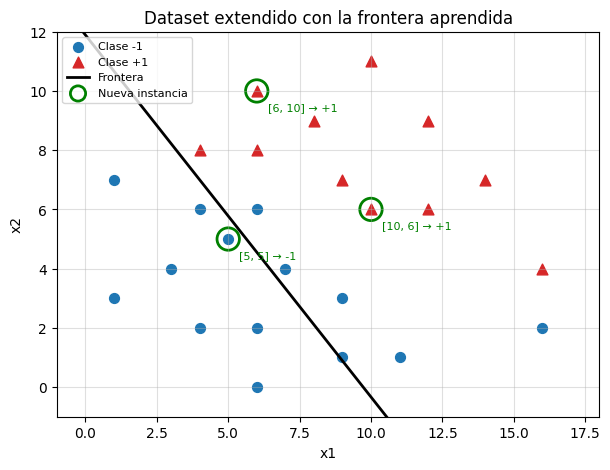

In [26]:
X_ext = [list(xi) for xi in X] + [list(xt) for xt in X_test]
y_ext = list(y) + list(y_test_pred)
print("Instancias en el dataset extendido:", len(X_ext))

ax = perceptron_plot(X_ext, y_ext, final_w, "Dataset extendido con la frontera aprendida", show=False)
# Resaltar las nuevas instancias
for xt, yp in zip(X_test, y_test_pred):
    ax.scatter(xt[0], xt[1], s=260, facecolors="none", edgecolors="green", linewidths=2)
    ax.annotate(f"{xt} → {yp:+d}", (xt[0], xt[1]), textcoords="offset points", xytext=(8, -14), fontsize=8, color="green")
ax.scatter([], [], s=120, facecolors="none", edgecolors="green", linewidths=2, label="Nueva instancia")
ax.legend(loc="upper left", fontsize=8)
plt.show()

**💬Pregunta guía:**
* ¿Las nuevas instancias quedaron ubicadas en la región esperada del plano?

*Sí, en términos generales quedaron ubicadas en las regiones correspondientes a los vecinos de su misma clase, aunque en este entrenamiento cambia cuál es el punto más cercano a la frontera.*
* ¿Alguna predicción parece discutible? Justifica tu respuesta.

* [6, 10] → +1 y [10, 6] → +1 son predicciones claras y sólidas. Ambas instancias quedan bien adentradas en la nube de los triángulos rojos (+1) y muy alejadas de la recta negra ($z = 24.50$ y $z = 28.50$, respectivamente). [6, 10] está justo encima de (6, 8) y cerca de (8, 9), mientras que [10, 6] está rodeado por vecinos +1 como (9, 7), (12, 6) y (12, 9). Incluso si el perceptrón hubiera encontrado la recta óptima que separa todas las clases, ambos puntos seguirían estando claramente en la región +1.

* [5, 5] → −1 es la predicción más discutible en este modelo. Aunque coincide con sus vecinos azules cercanos como (4, 6), (3, 4) y (6, 6), quedó ubicado prácticamente pegado a la frontera de decisión ($z = -3.50$, el valor absoluto más pequeño de los tres). Dado que el perceptrón se detuvo sin converger en una recta demasiado inclinada, este punto queda en una zona de margen mínimo: si la frontera tuviera la inclinación más suave que realmente separa los datos (pasando entre (6, 6) y (6, 8)), [5, 5] quedaría mucho más holgado dentro de la región −1, pero con esta recta específica cualquier ligera variación en los pesos o la tasa de aprendizaje podría cruzarlo al lado +1.


#**📖Fase 7** *- Evolución de la Frontera de Decisión*

*El entrenamiento del perceptrón modifica gradualmente los pesos. Como los  pesos determinan la frontera de decisión, es posible observar cómo cambia la recta durante el aprendizaje.*



---





##**Actividad 7.a***— Seis estados del entrenamiento*
*Crea seis gráficas diferentes que muestren la evolución de la frontera de decisión. Selecciona los siguientes momentos:*
* *Estado inicial*
* *20% del entrenamiento*
* *40% del entrenamiento*
* *60% del entrenamiento*
* *80% del entrenamiento*
* *Estado final*

*Si el entrenamiento tuvo menos de seis épocas, grafica todos los estados disponibles.*

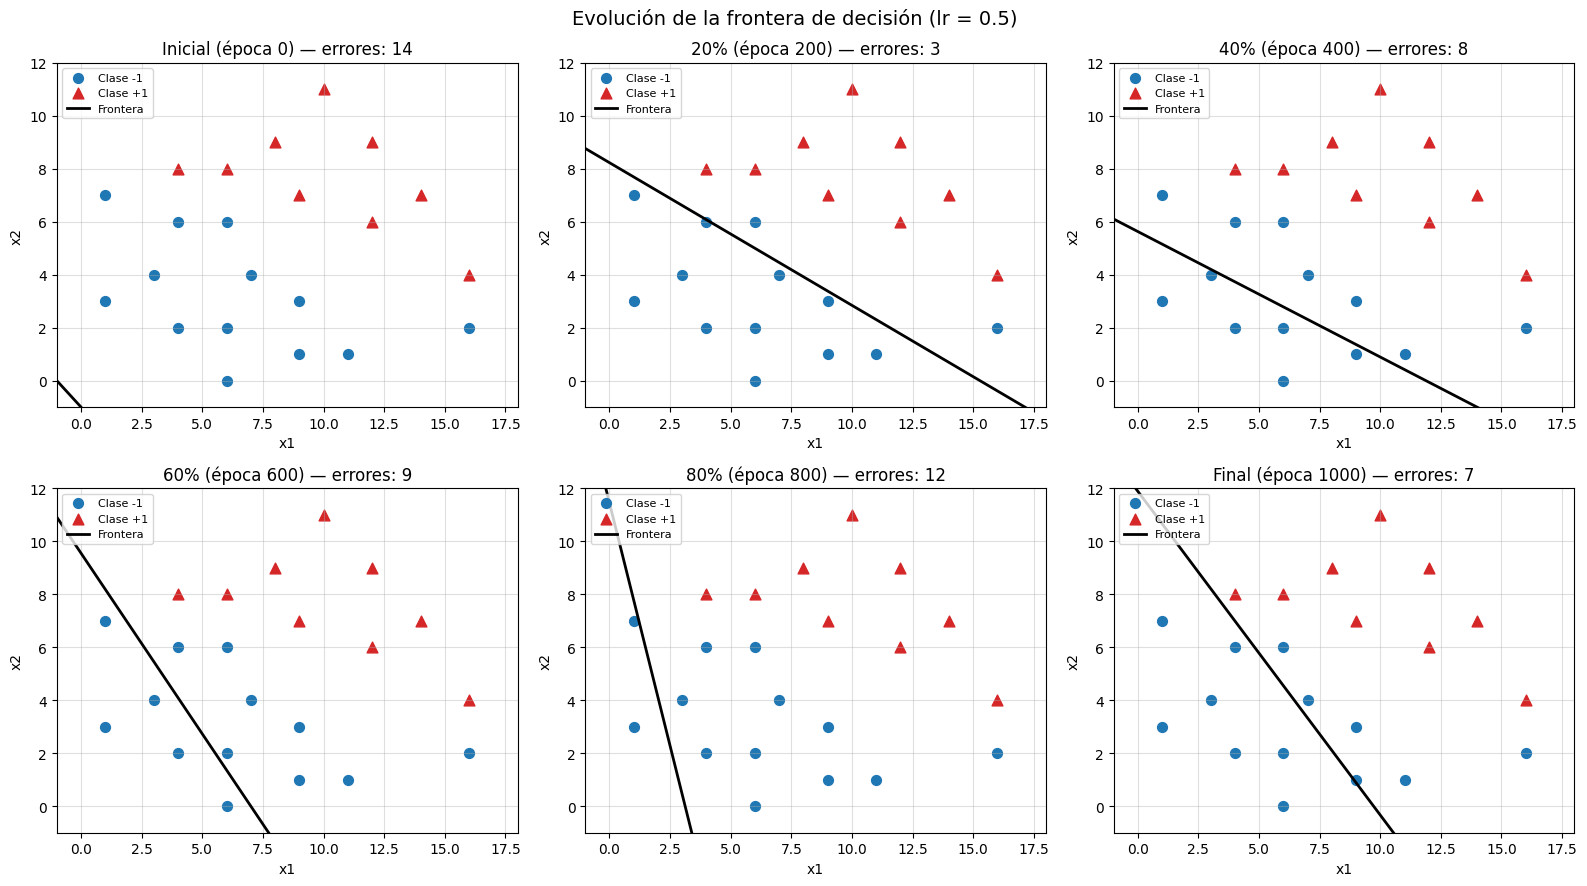

Épocas graficadas: [0, 200, 400, 600, 800, 1000]
época    0: w = [    0.50,   0.50,   0.50]   pendiente =  -1.000   corte x2 =  -1.000
época  200: w = [  -53.50,   3.50,   6.50]   pendiente =  -0.538   corte x2 =   8.231
época  400: w = [  -53.50,   4.50,   9.50]   pendiente =  -0.474   corte x2 =   5.632
época  600: w = [  -52.50,   7.50,   5.50]   pendiente =  -1.364   corte x2 =   9.545
época  800: w = [  -51.50,  16.50,   4.50]   pendiente =  -3.667   corte x2 =  11.444
época 1000: w = [  -53.50,   5.50,   4.50]   pendiente =  -1.222   corte x2 =  11.889


In [27]:
def plot_evolution(X, y, W_values, lr_label=""):
    n_states = len(W_values)
    if n_states <= 6:
        indices = list(range(n_states))
        names = ["Inicial"] + [f"Época {k}" for k in range(1, n_states)]
    else:
        porcentajes = [0, 0.2, 0.4, 0.6, 0.8, 1.0]
        indices = [round(p * (n_states - 1)) for p in porcentajes]
        names = ["Inicial", "20%", "40%", "60%", "80%", "Final"]

    fig, axes = plt.subplots(2, 3, figsize=(16, 9))
    axes = axes.flatten()
    for ax, idx, name in zip(axes, indices, names):
        wk = W_values[idx]
        errs = sum(1 for xi, yi in zip(X, y) if perceptron_compute(xi, wk) != yi)
        perceptron_plot(X, y, wk, f"{name} (época {idx}) — errores: {errs}", ax=ax, show=False)
    for ax in axes[len(indices):]:
        ax.axis("off")
    fig.suptitle(f"Evolución de la frontera de decisión {lr_label}", fontsize=14)
    plt.tight_layout()
    plt.show()
    return indices

idx_05 = plot_evolution(X, y, W_values, "(lr = 0.5)")
print("Épocas graficadas:", idx_05)
for i in idx_05:
    wk = W_values[i]
    print(f"época {i:4d}: w = [{wk[0]:8.2f}, {wk[1]:6.2f}, {wk[2]:6.2f}]   "
          f"pendiente = {-wk[1]/wk[2]:7.3f}   corte x2 = {-wk[0]/wk[2]:7.3f}")

**💬Pregunta guía:**
* *¿Qué ocurre con la frontera de decisión a medida que se actualizan los pesos?*

*A medida que se actualizan los pesos, la frontera de decisión oscila y rota continuamente alrededor de la nube de puntos sin lograr estabilizarse en una posición que separe ambas clases. El cambio es marcadamente brusco e inestable.*
* *¿El cambio parece estable o brusco?*

Se observa en tres aspectos clave de las gráficas y los registros de pesos:

1. *Desplazamiento inicial y retroceso en el desempeño, podemos ver que en la época 0, la recta (corte x2 = -1.000, pendiente = -1.000) empieza en la esquina inferior izquierda dejando todos los puntos azules mal clasificados (14 errores). Para la época 200, sube y se acomoda cerca del hueco entre ambas clases (corte x2 = 8.231, pendiente = -0.538), reduciendo los errores a su mínimo registrado en la secuencia (3 errores). Sin embargo, en lugar de converger hacia el cero, el modelo sigue ajustando los pesos y empieza a empeorar: sube a 8 errores en la época 400, 9 en la 600 y 12 en la 800, terminando con 7 errores en la época 1000.*

2. *Giros abruptos de pendiente, como boservamos la inclinación de la recta sufre saltos drásticos entre etapas. Pasa de una pendiente suave de -0.474 en la época 400 a inclinarse violentamente hasta -1.364 en la época 600 y casi verticalizarse en -3.667 en la época 800 (donde el peso $w_1$ salta bruscamente de 7.50 a 16.50), para luego volver a retroceder a -1.222 en la época 1000.*

3. *Causa de la inestabilidad ya que esta falta de convergencia ocurre porque la tasa de aprendizaje (lr = 0.5) es demasiado alta en relación con el orden en que se evalúan los datos. Cada vez que el perceptrón intenta corregir un punto mal clasificado (como los círculos azules situados más a la derecha en (9, 3) o (16, 2)), el paso de actualización es tan grande que empuja y rota la recta en exceso, desacomodando puntos que ya estaban bien clasificados y generando un ciclo perpetuo de sobrecorrección.*


##**Actividad 7.b** *— Interpretación geométrica*
*Analiza cómo se desplaza o rota la recta durante el entrenamiento.*

**💬Pregunta guía:**
* ¿Qué peso parece influir más en la inclinación de la recta?

*Peso que más influye en la inclinación ($w_1$): Aunque matemáticamente la pendiente depende de la relación entre $w_1$ y $w_2$, en estos datos es $w_1$ (el peso asociado a $x_1$) el que provoca los cambios más drásticos en la inclinación. Mientras que $w_2$ se mantiene en un rango moderado (entre 4.50 y 9.50), $w_1$ sufre variaciones muy bruscas (3.50 $\rightarrow$ 7.50 $\rightarrow$ 16.50 $\rightarrow$ 5.50). Esto se ve con claridad en la época 800, donde el salto de $w_1$ a 16.50 hace que la pendiente caiga abruptamente a -3.667, y al bajar $w_1$ a 5.50 en la época 1000, la pendiente se suaviza de nuevo a -1.222.*

* ¿Qué papel parece cumplir el bias en el desplazamiento de la frontera?

*Papel del bias ($w_0$) en el desplazamiento: El bias actúa como un término de traslación que mueve la recta hacia arriba o hacia abajo en el plano (determinando el corte con el eje $x_2 = -w_0/w_2$) sin modificar su inclinación. En la época 0, con un bias positivo (0.50), la recta queda desplazada hacia abajo fuera de la nube de datos (corte x2 = -1.000). Al ajustarse a valores negativos grandes (alrededor de -53.50 desde la época 200 en adelante), el bias empuja la frontera hacia arriba (corte x2 entre 5.632 y 11.889), situándola justo en la zona donde se encuentran las instancias. Una vez que $w_0$ se estabiliza cerca de -53.50, las variaciones menores en la altura del corte pasan a depender de los ajustes en $w_2$.*  

* **Comentario sobre la evolución observada:**

*A lo largo de las 1000 épocas se observa una evolución no convergente y altamente oscilatoria. Aunque el conjunto de datos es linealmente separable (como se evidencia en la distribución de ambas nubes de puntos), esta ejecución con tasa de aprendizaje lr = 0.5 y pesos iniciales [0.5, 0.5, 0.5] no logra estabilizarse:*
* *El bias ($w_0$) logra estabilizarse temprano alrededor de -53.50 (manteniendo la recta a una altura adecuada), pero los pesos asociados a las coordenadas —especialmente $w_1$— sufren fluctuaciones bruscas. Al intentar corregir los puntos más extremos de la clase −1 (como (9, 3) y (16, 2)), el paso de actualización resulta demasiado grande y provoca giros abruptos en la pendiente (llegando a -3.667 en la época 800), desclasificando instancias que ya estaban bien ubicadas.*

* *Tras partir en la época 0 completamente fuera de la región de los datos (14 errores), el perceptrón logra desplazarse rápidamente hacia el espacio entre clases, alcanzando su mejor desempeño alrededor de la época 200 (con solo 3 errores y una pendiente suave de -0.538). Sin embargo, en lugar de afinar ese margen hacia cero, las actualizaciones posteriores degradan la solución, elevando los errores hasta 12 en la época 800.*

#**📖Fase 8** *- Evolución del Error*

Además de observar la frontera de decisión, es necesario analizar cómo cambia el error durante el entrenamiento.



---



##**Actividad 8.a** *— Gráfica de error*

*Crea una función llamada plot_error(E_values, title) La función debe graficar:*
* *Eje X: época*
* *Eje Y: tasa de error*
* *Título*
* *Cuadrícula*
*Luego grafica la evolución del error para el entrenamiento con lr = 0.5.*

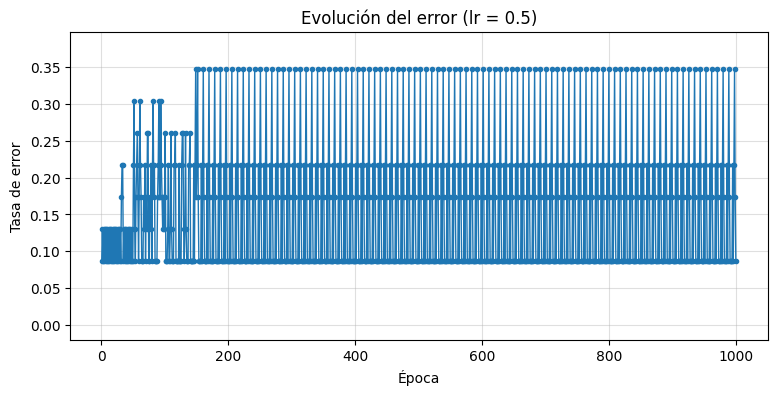

Error máximo: 0.348 | Error final: 0.08695652173913043


In [28]:
def plot_error(E_values, title, ax=None):
    show = ax is None
    if ax is None:
        fig, ax = plt.subplots(figsize=(9, 4))
    epocas = list(range(1, len(E_values) + 1))
    ax.plot(epocas, E_values, marker=".", linewidth=1)
    ax.set_xlabel("Época"); ax.set_ylabel("Tasa de error")
    ax.set_title(title); ax.grid(True, alpha=0.4)
    ax.set_ylim(-0.02, max(E_values) + 0.05)
    if show:
        plt.show()

plot_error(E_values, "Evolución del error (lr = 0.5)")
print("Error máximo:", round(max(E_values), 3), "| Error final:", E_values[-1])

**💬Pregunta guía:**
* *¿El error disminuye de forma continua en todas las épocas?*

*No, el error no disminuye de forma continua. Por el contrario, presenta fuertes oscilaciones desde el inicio y, a partir de aproximadamente la época 150, queda atrapado en un ciclo periódico repetitivo donde rebota constantemente entre un error mínimo de 0.087 (2 de 23 instancias mal clasificadas) y un error máximo de 0.348 (8 de 23 instancias mal clasificadas) hasta llegar al límite de las 1000 épocas.*
* *Si no ocurre así, ¿por qué puede aumentar o mantenerse igual durante algunos momentos del entrenamiento?*

*Este comportamiento ocurre por tres razones propias del algoritmo del perceptrón:*

1. *Por qué aumenta (corrección local sin visión global): El perceptrón actualiza los pesos cada vez que encuentra una instancia mal clasificada ($w \leftarrow w + \eta \cdot y_i \cdot x_i$), sin verificar si ese movimiento empeora el resto. Con una tasa de aprendizaje alta (lr = 0.5), el desplazamiento o giro de la recta para corregir un punto extremo suele ser tan brusco que deja mal clasificados a varios puntos que antes estaban en el lado correcto, provocando saltos abruptos en la tasa de error (hasta 0.348).*

2. *Por qué se mantiene igual (métrica discreta escalonada): La tasa de error es una función discreta que cuenta la proporción exacta de puntos equivocados ($k/23$). Si entre una época y otra los pesos cambian pero la recta se mueve dentro de un espacio vacío sin cruzar ningún punto del dataset, el conteo de errores permanece idéntico (generando los niveles horizontales repetidos que se ven en 0.087, 0.174, 0.217 y 0.348).*

3. *Por qué entra en bucle (ciclo límite): Al recorrer las instancias en el mismo orden en cada época y aplicar correcciones de magnitud fija (lr = 0.5), el modelo entra en un estado de sobrecorrección cíclica: ajusta la recta para resolver un grupo de errores, pero ese nuevo estado genera otros errores que en las siguientes iteraciones empujan la recta de vuelta a su posición anterior, impidiendo que el error llegue a cero.*

##**Actividad 8.b** *— Análisis de convergencia*
*Observa la última época del entrenamiento.*

**💬Pregunta guía:**
* *¿Qué significa que el error final sea igual a cero?*

*Significa que el perceptrón logró converger y encontró una frontera de decisión lineal que clasifica correctamente el 100 % de las instancias del conjunto de entrenamiento (por ejemplo, las 23 instancias del dataset original). Técnicamente, confirma dos hechos: que los datos de entrenamiento son linealmente separables y que el algoritmo completó una época entera sin cometer ningún fallo, por lo que dejó de actualizar los pesos.*
* ¿Significa que el modelo es perfecto para cualquier dato futuro? Justifica tu respuesta.

*No. Alcanzar un error de 0.0 en el entrenamiento solo mide el ajuste sobre los datos ya conocidos, pero no garantiza una generalización perfecta ante instancias nuevas por tres razones:*

1. *Ausencia de margen máximo: El perceptrón se detiene en cuanto encuentra la primera recta que separa las clases sin error, sin buscar la que deje mayor distancia respecto a los puntos más cercanos. Si la frontera queda muy pegada a los bordes de una clase (como se observó en las regiones cercanas a la recta en la gráfica extendida), cualquier dato futuro ligeramente desplazado en esa zona límite será clasificado de forma errónea.*

2. *Múltiples soluciones posibles: En un conjunto linealmente separable existen infinitas rectas que logran error cero. Dependiendo de los pesos iniciales, la tasa de aprendizaje o el orden de los datos, el modelo obtendrá una recta distinta, lo que hace que sus predicciones en zonas intermedias sean sensibles e inestables.*

3. *Representatividad limitada y ruido: El entrenamiento se realiza sobre una muestra finita (en este caso, 23 puntos). Si los datos futuros contienen ruido, valores atípicos o provienen de una frontera real que no es estrictamente lineal, el modelo lineal cometerá errores al intentar generalizar.*

* **Análisis de convergencia:**

*Con los hiperparámetros configurados (pesos iniciales [0.5, 0.5, 0.5], tasa de aprendizaje lr = 0.5 y límite de 1000 épocas), el perceptrón no alcanzó la convergencia. Aunque el conjunto de 23 instancias es linealmente separable, el entrenamiento agotó el máximo de iteraciones sin lograr anular el error.*

*Los indicadores principales de este comportamiento son:*

* *Detención por límite de épocas y error residual: El algoritmo ejecutó las 1000 épocas completas realizando 3524 actualizaciones. El error final (E_values[-1]) cerró en 0.087 (0.0869565...), equivalente a 2 instancias mal clasificadas de 23 ((9, 3) y (16, 2) de la clase −1 quedaron ubicadas por encima de la recta final $x_2 = -1.222 \cdot x_1 + 11.889$).*

* *Ciclo límite oscilatorio: Desde las primeras iteraciones, el error alterna sin estabilizarse ([0.087, 0.13, 0.087, 0.13, ...]). A partir de aproximadamente la época 150, la curva entra en un patrón periódico repetitivo donde la tasa de error rebota constantemente entre un mínimo de 0.087 (2 errores) y un máximo de 0.348 (8 errores) hasta el final del entrenamiento.*

#**📖Fase 9** *- Comparación de Tasas de Aprendizaje*

*La tasa de aprendizaje controla la magnitud de los cambios aplicados a los pesos cuando el perceptrón comete un error. En esta fase repetirás el entrenamiento con:*

* *lr = 0.3*
* *lr = 0.5*
* *lr = 0.8*

*Para que la comparación sea justa, debes usar los mismos pesos iniciales en los tres experimentos.*


---



##**Actividad 9.a** *— Entrenamiento comparativo*

*Inicializa un único vector de pesos iniciales y crea copias para cada valor de lr. Para cada tasa de aprendizaje, registra:*

* *Pesos finales*
* *Número de épocas*
* *Número total de actualizaciones*
* *Error final*


In [29]:
w_comun = initialize_weights()
print("Pesos iniciales comunes:", [round(v, 4) for v in w_comun])

learning_rates = [0.3, 0.5, 0.8]
resultados = {}
for lr in learning_rates:
    w_copia = list(w_comun)
    fw, ep, upd, Wv, Ev = perceptron_learning(X, y, w_copia, lr=lr, max_epochs=1000)
    resultados[lr] = {"w": fw, "epochs": ep, "updates": upd, "W_values": Wv, "E_values": Ev}
    print(f"lr = {lr}:  épocas = {ep:4d} | actualizaciones = {upd:4d} | error final = {Ev[-1]} | "
          f"pesos finales = {[round(v, 3) for v in fw]}")

# Verificación: los pesos iniciales no se modificaron
print("w_comun sigue intacto:", [round(v, 4) for v in w_comun])

Pesos iniciales comunes: [0.5, 0.5, 0.5]
lr = 0.3:  épocas = 1000 | actualizaciones = 3342 | error final = 0.21739130434782608 | pesos finales = [-25.9, 4.7, -1.9]
lr = 0.5:  épocas = 1000 | actualizaciones = 3524 | error final = 0.08695652173913043 | pesos finales = [-53.5, 5.5, 4.5]
lr = 0.8:  épocas = 1000 | actualizaciones = 3693 | error final = 0.21739130434782608 | pesos finales = [-77.9, 14.9, -5.9]
w_comun sigue intacto: [0.5, 0.5, 0.5]


**💬Pregunta guía:**
* ¿Por qué no sería justo comparar las tasas de aprendizaje usando pesos iniciales diferentes?

*Porque el número de épocas y de actualizaciones depende mucho del punto de partida: una recta inicial que por azar ya está cerca de la solución converge rápido, y una que está lejos tarda más. Si cada lr empezara con pesos distintos, no podríamos saber si la diferencia en épocas se debe a la tasa de aprendizaje o a la “suerte” de la inicialización. Al usar los mismos pesos iniciales se controla esa variable y lr es lo único que cambia entre experimentos.*

##**Actividad 9.b** *— Gráficas comparativas*

*Para cada valor de lr, genera:*
* *seis gráficas de evolución de la frontera;*
* *gráfica de evolución del error.*


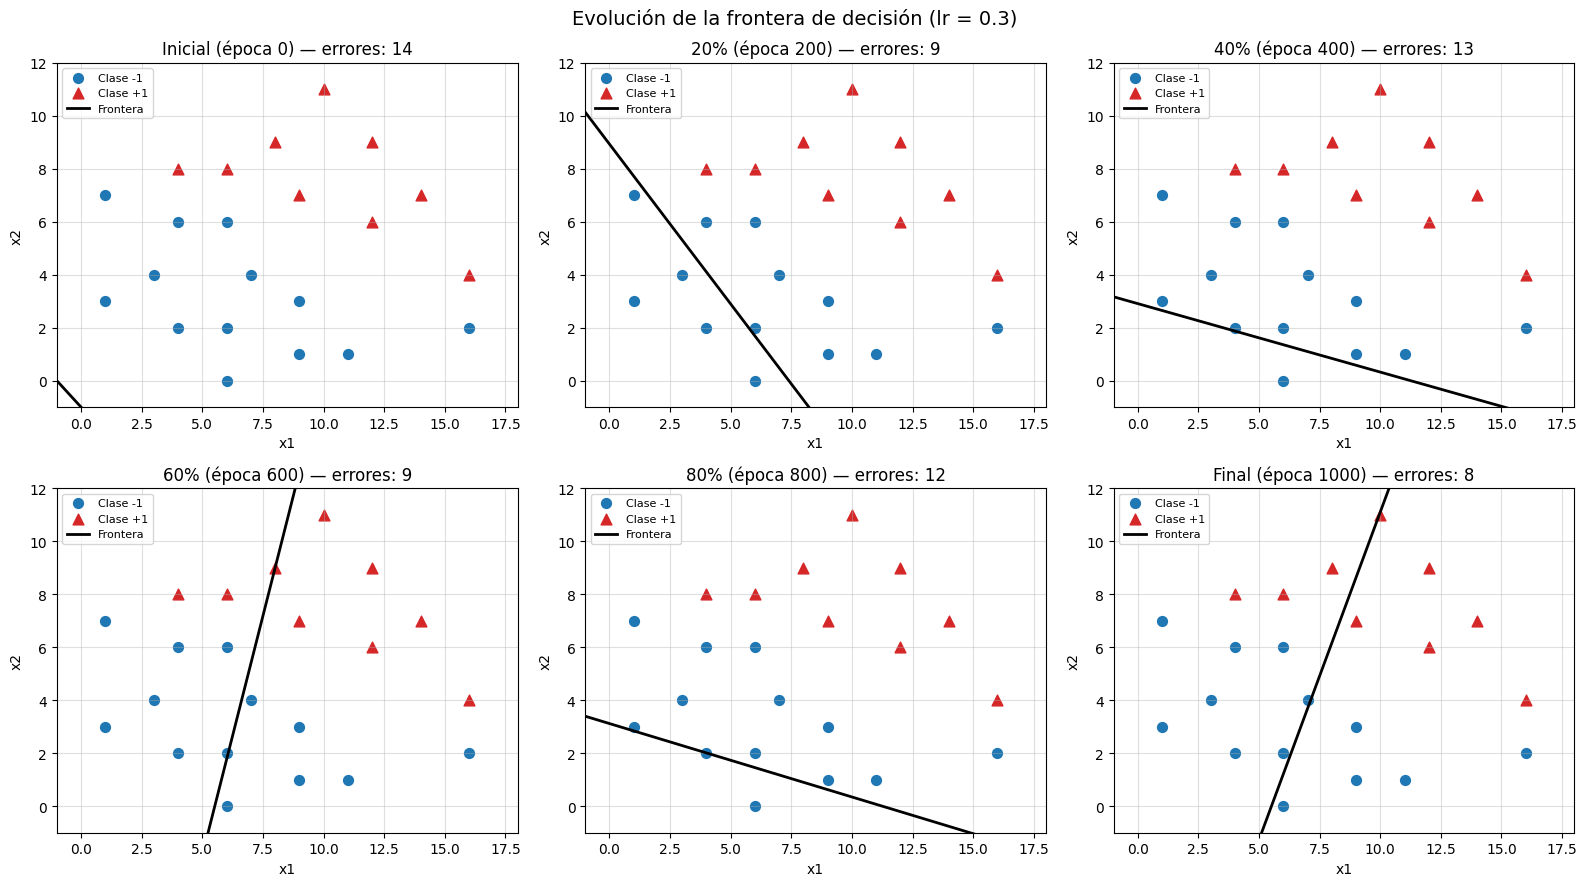

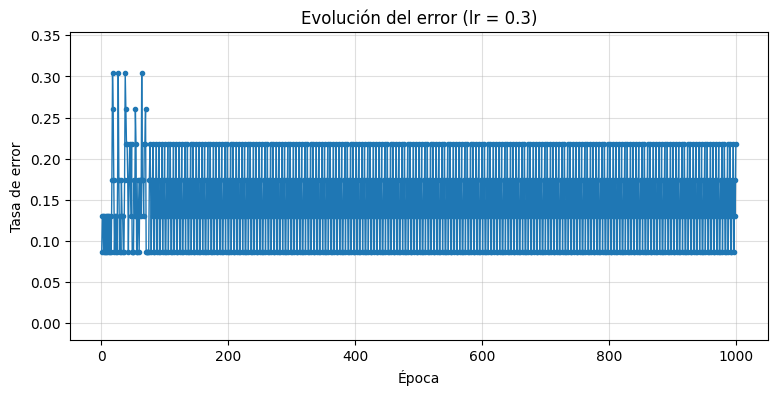

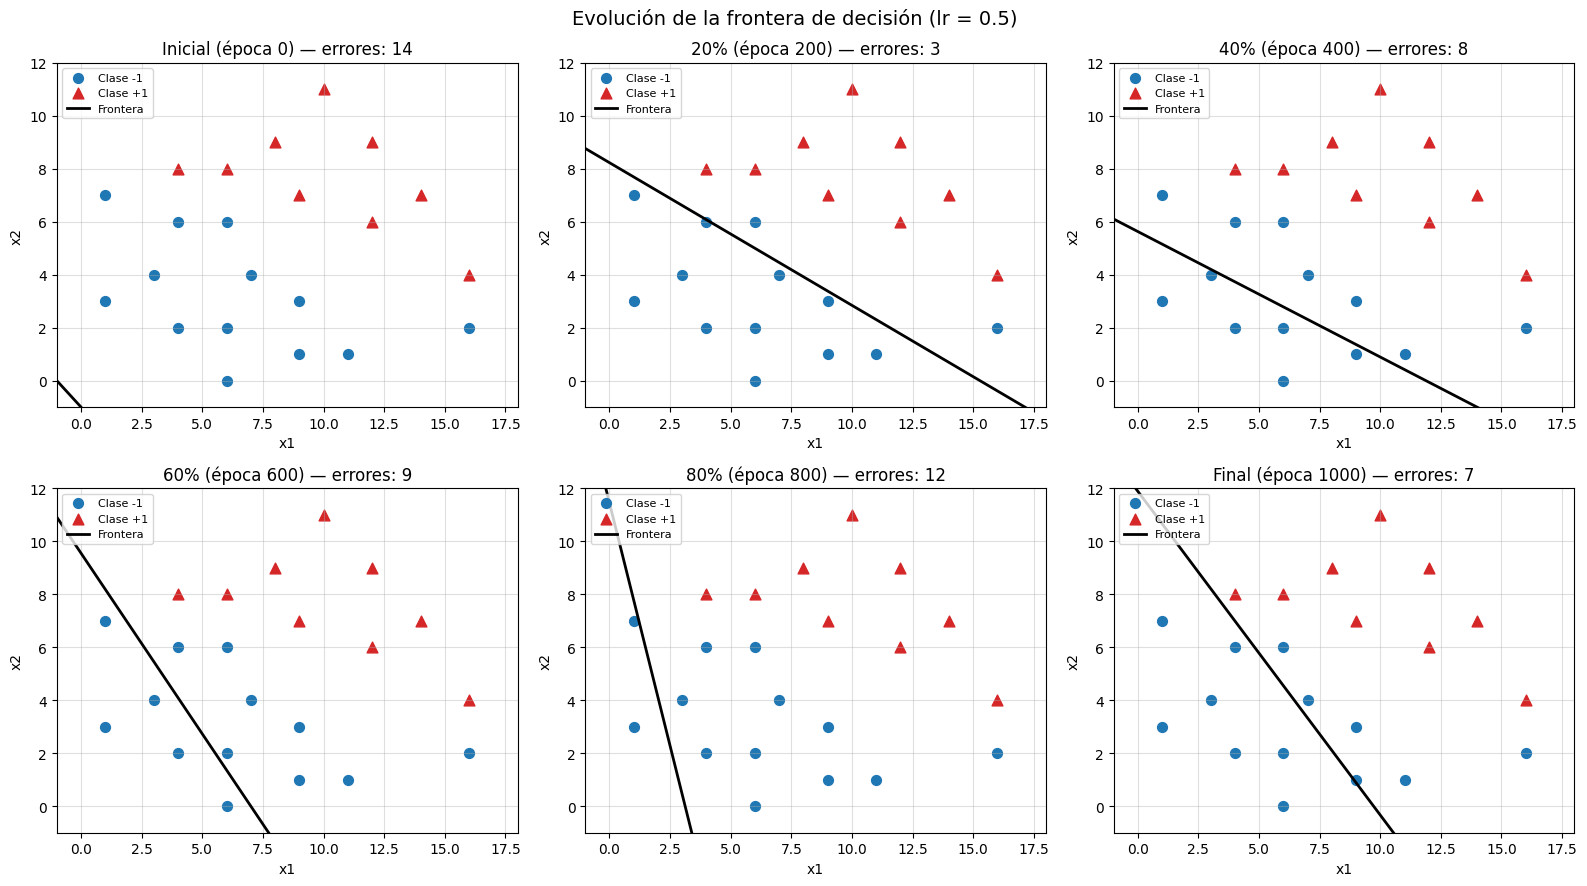

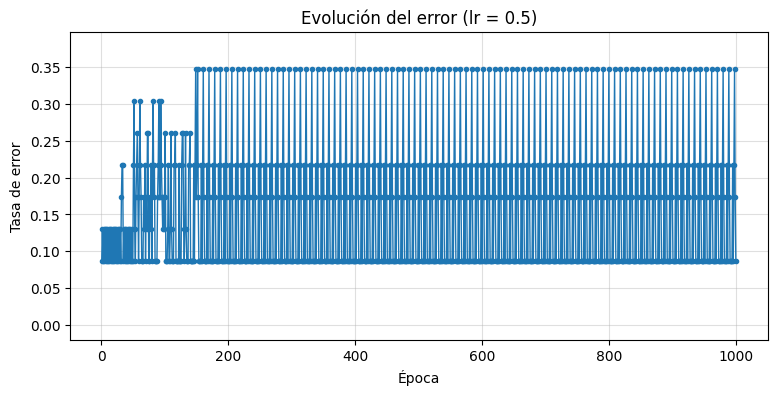

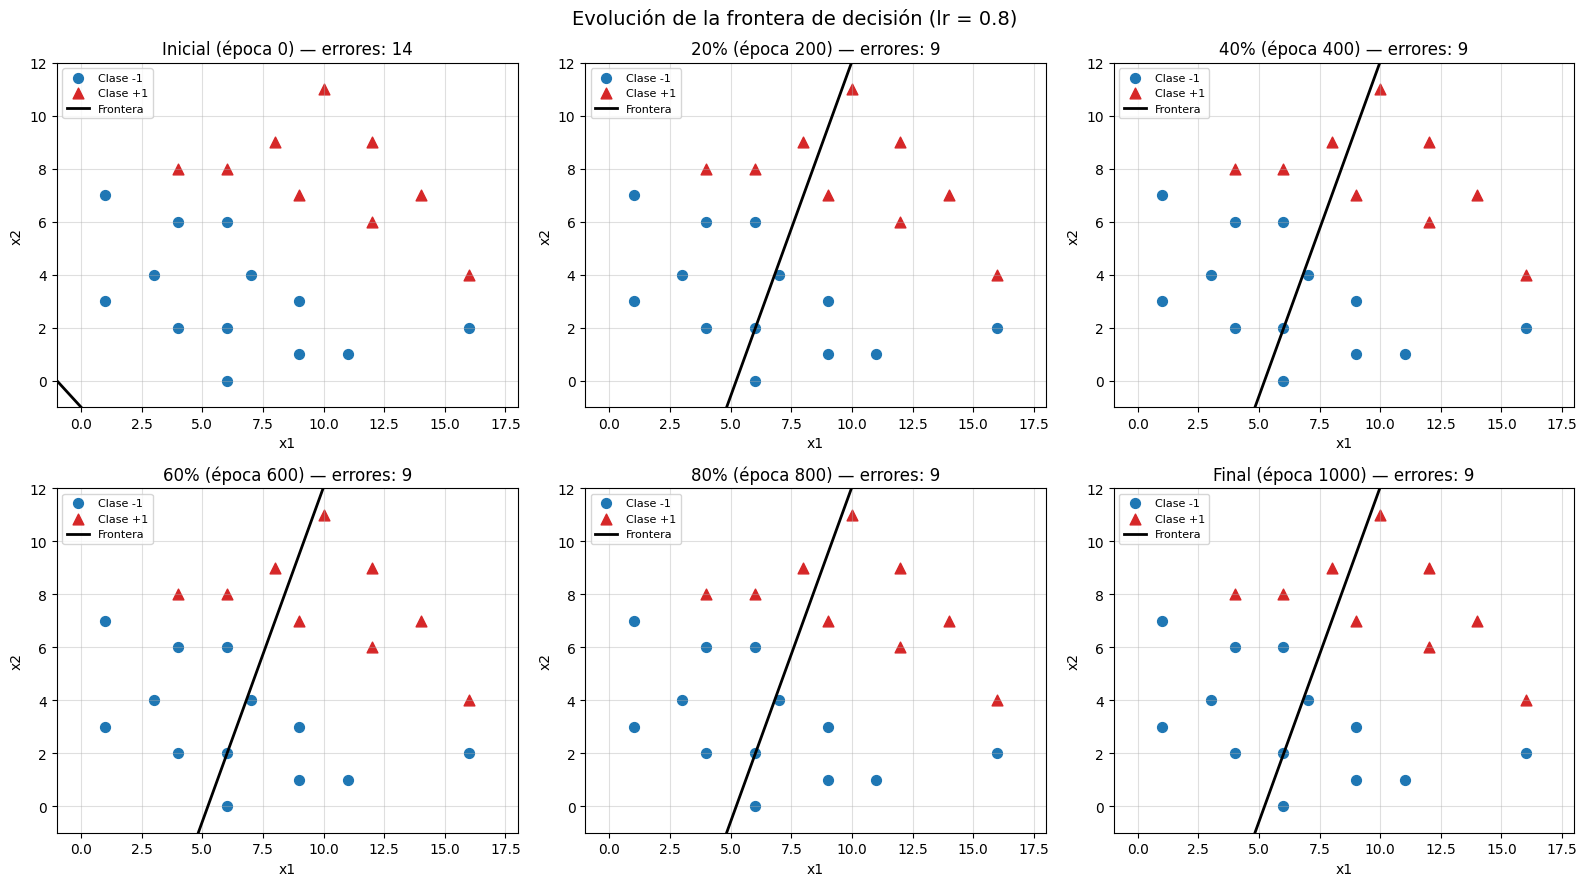

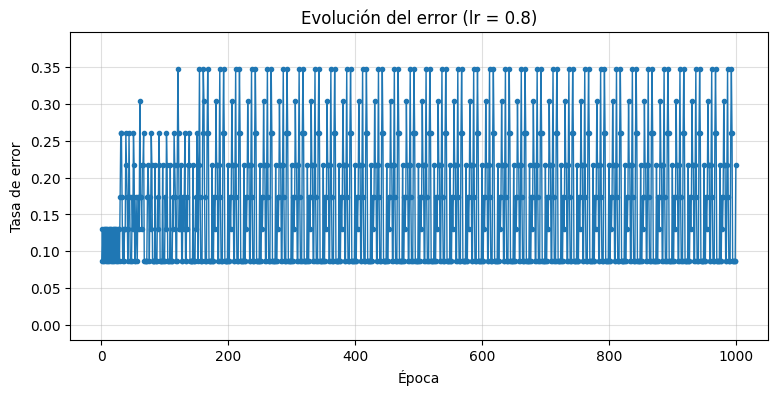

In [30]:
for lr in learning_rates:
    r = resultados[lr]
    idx = plot_evolution(X, y, r["W_values"], f"(lr = {lr})")
    plot_error(r["E_values"], f"Evolución del error (lr = {lr})")

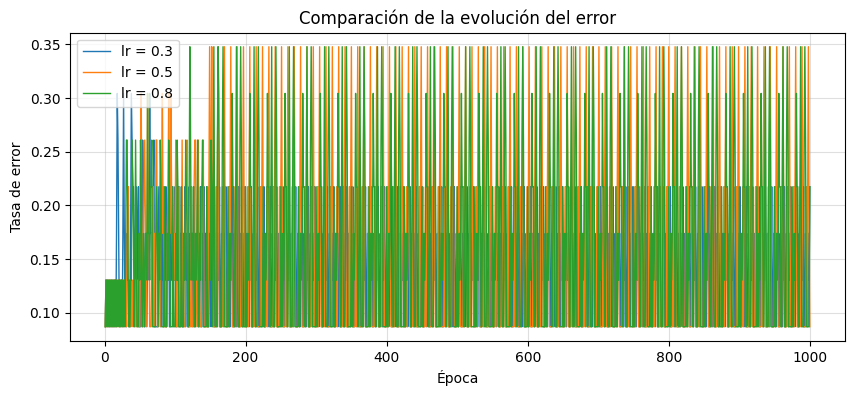

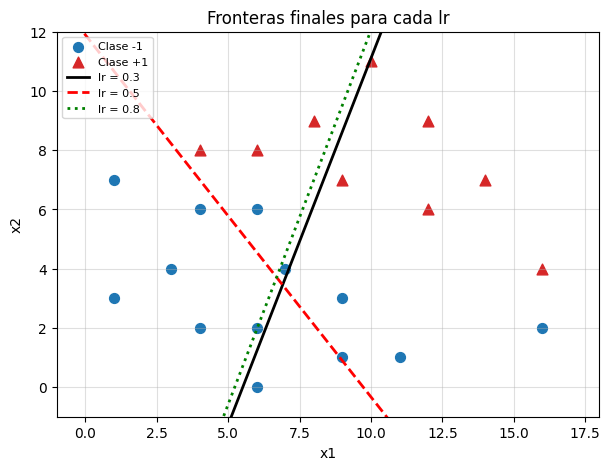

In [31]:
# Comparación de las tres curvas de error en una sola figura
fig, ax = plt.subplots(figsize=(10, 4))
for lr in learning_rates:
    Ev = resultados[lr]["E_values"]
    ax.plot(range(1, len(Ev) + 1), Ev, linewidth=1, label=f"lr = {lr}")
ax.set_xlabel("Época"); ax.set_ylabel("Tasa de error")
ax.set_title("Comparación de la evolución del error"); ax.grid(True, alpha=0.4); ax.legend()
plt.show()

# Fronteras finales superpuestas
fig, ax = plt.subplots(figsize=(7, 5))
perceptron_plot(X, y, resultados[0.3]["w"], "Fronteras finales para cada lr", ax=ax, show=False)
ax.lines[0].set_label("lr = 0.3")
for lr, estilo in [(0.5, "r--"), (0.8, "g:")]:
    fw = resultados[lr]["w"]
    ax.plot([X1_MIN, X1_MAX], [-(fw[1]/fw[2])*x - fw[0]/fw[2] for x in [X1_MIN, X1_MAX]], estilo, linewidth=2, label=f"lr = {lr}")
ax.legend(loc="upper left", fontsize=8)
plt.show()

**💬Pregunta guía:**
* *¿Qué tasa de aprendizaje permitió alcanzar la convergencia con menos épocas?*

*Ninguna de las tres. Al revisar las gráficas de evolución completa, ninguna tasa de aprendizaje (0.3, 0.5 ni 0.8) logró converger, ya que todas llegaron al límite máximo de 1000 épocas sin reducir los errores a cero:*
* *Con lr = 0.3, la recta oscila sin estabilizarse durante todo el proceso, registrando 14 errores en la época 0, 9 en la 200, 13 en la 400, 9 en la 600, 12 en la 800 y cerrando con 7 errores en la época 1000.*

* *Con lr = 0.5, la tasa de error queda atrapada en un ciclo periódico continuo entre ~0.087 y ~0.348 hasta la época 1000.*

* *Con lr = 0.8, la curva de error también rebota periódicamente entre ~0.087 y ~0.348, y en todos los puntos de control (épocas 200, 400, 600, 800 y 1000) la frontera aparece atascada con 9 errores y una pendiente positiva que corta transversalmente ambas clases.*


* ¿Eso significa necesariamente que es la mejor tasa de aprendizaje?

*No, por dos razones principales:*

1. *Velocidad no equivale a estabilidad ni a convergencia: Como se observa en estas ejecuciones, tasas demasiado altas provocan sobrecorrecciones bruscas en cada actualización; en el caso de lr = 0.8, el paso es tan grande que la recta gira hasta adquirir una pendiente positiva errónea y queda encerrada en un ciclo repetitivo de 9 errores desde la época 200 en adelante.*

2. *Calidad de la frontera (margen): Incluso en escenarios (con otros pesos iniciales) donde una tasa alta logre converger en menos épocas que una baja, el perceptrón detiene el entrenamiento en cuanto encuentra la primera recta que clasifica sin fallos, sin maximizar el margen de separación. Una tasa más moderada produce ajustes más suaves y controlados, reduciendo el riesgo de que la frontera quede pegada a los puntos límite o gire abruptamente por un dato extremo.*

##**Actividad 9.c** *— Tabla comparativa*

*Construye una tabla como la siguiente:*

In [32]:
print(f"{'lr':<6}{'Épocas':>8}{'Actualizaciones':>18}{'Error final':>14}   Pesos finales [w0, w1, w2]")
print("-" * 82)
for lr in learning_rates:
    r = resultados[lr]
    pesos = "[" + ", ".join(f"{v:.3f}" for v in r["w"]) + "]"
    print(f"{lr:<6}{r['epochs']:>8}{r['updates']:>18}{r['E_values'][-1]:>14.2f}   {pesos}")

print("\nRectas finales (x2 = m·x1 + b):")
for lr in learning_rates:
    fw = resultados[lr]["w"]
    print(f"  lr = {lr}: m = {-fw[1]/fw[2]:.3f}, b = {-fw[0]/fw[2]:.3f}")

lr      Épocas   Actualizaciones   Error final   Pesos finales [w0, w1, w2]
----------------------------------------------------------------------------------
0.3       1000              3342          0.22   [-25.900, 4.700, -1.900]
0.5       1000              3524          0.09   [-53.500, 5.500, 4.500]
0.8       1000              3693          0.22   [-77.900, 14.900, -5.900]

Rectas finales (x2 = m·x1 + b):
  lr = 0.3: m = 2.474, b = -13.632
  lr = 0.5: m = -1.222, b = 11.889
  lr = 0.8: m = 2.525, b = -13.203


| lr | Épocas | Actualizaciones | Error final | Pesos finales [w0, w1, w2] |
|:---:|:---:|:---:|:---:|:---|
| 0.3 | 1000 | 3342 | 0.22 | [−25.900, 4.700, −1.900] |
| 0.5 | 1000 | 3524 | 0.09 | [−53.500, 5.500, 4.500] |
| 0.8 | 1000 | 3693 | 0.22 | [−77.900, 14.900, −5.900] |

**💬Pregunta guía:**
* *¿Los pesos finales son iguales para todas las tasas de aprendizaje?*

*No. Cada tasa de aprendizaje produce un vector de pesos distinto en magnitud y, en este caso, incluso en el signo de $w_2$. Esto ocurre porque el tamaño del paso (lr) altera directamente cuánto se modifican los pesos en cada error, haciendo que el algoritmo siga trayectorias de ajuste diferentes (acumulando 3342, 3524 y 3693 actualizaciones respectivamente).*

* *Si son diferentes, ¿por qué pueden producir igualmente una clasificación correcta?*

*Existen dos razones geométricas y matemáticas por las que distintos vectores de pesos clasifican igual de bien:*

1. *Invariancia ante escalamiento (proporcionalidad): La ecuación de la frontera de decisión ($w_0 + w_1 x_1 + w_2 x_2 = 0$, o $x_2 = -\frac{w_1}{w_2}x_1 - \frac{w_0}{w_2}$) no depende de la magnitud absoluta de los pesos, sino de las proporciones entre ellos. Si un vector de pesos se multiplica por una constante positiva, los números cambian pero la recta en el plano es exactamente la misma (solo crece la magnitud de $z = w \cdot x$, manteniendo su signo). Esto se aprecia claramente comparando lr = 0.3 ([-25.900, 4.700, -1.900]) y lr = 0.8 ([-77.900, 14.900, -5.900]): aunque los pesos de 0.8 son aproximadamente el triple de grandes, sus proporciones son casi idénticas y generan prácticamente la misma recta (m = 2.474, b = -13.632 frente a m = 2.525, b = -13.203) y exactamente el mismo error (0.22).*

2. *Infinitas fronteras válidas entre clases separables: Cuando el perceptrón sí alcanza la convergencia (error 0.00), en un dataset linealmente separable no existe una única recta solución, sino infinitas rectas con distintas pendientes e interceptos que atraviesan el margen vacío entre ambas nubes de puntos. Como cada tasa de aprendizaje detiene el entrenamiento en cuanto encuentra la primera recta sin errores, cada ejecución puede terminar con pesos no proporcionales entre sí (rectas ligeramente distintas en posición o inclinación) que aun así separan el 100 % de las instancias correctamente.*

#**🎯Conclusiones**

---



1. *El perceptrón converge porque el dataset es linealmente separable, pero el número de épocas necesario (≈ 100–300) es grande para solo 23 puntos: el margen entre clases es estrecho, sobre todo en la zona x1 ≈ 12–16, y la mayoría de épocas se gastan corrigiendo esos pocos puntos cercanos a la frontera.*
2. *La curva de error no es monótona: las actualizaciones punto a punto provocan oscilaciones (el error sube hasta 0.30 y baja) y la caída a cero ocurre de forma abrupta al final, por lo que una época con error alto no indica que el entrenamiento esté fallando.*
3. *Geométricamente, el bias evoluciona de forma ordenada (traslada la recta hacia arriba poco a poco), mientras que w1 provoca rotaciones bruscas; la escala de x1 (hasta 16) hace que cada corrección sea grande respecto a los pesos.*

#**🚀Recomendaciones**


---



1. *Normalizar o escalar los datos antes de entrenar. Las coordenadas llegan hasta 16, así que cada corrección cambia mucho los pesos (sobre todo w1) y la frontera gira de forma brusca entre épocas. Escalar x1 y x2 a un rango como [0, 1] o [−1, 1] daría un entrenamiento más estable y probablemente con menos épocas.*

2. *Repetir los experimentos con varias semillas antes de comparar tasas de aprendizaje. Con una sola inicialización, lr = 0.5 fue la más rápida, pero con otras semillas el orden cambia. Conviene entrenar varias veces cada lr y comparar el promedio de épocas y actualizaciones, porque un solo experimento no basta para decir cuál es la mejor.*

3. *Evaluar el modelo con datos de prueba que tengan etiqueta real. Un error de 0 en entrenamiento solo dice que el perceptrón separó esos 23 puntos, no que vaya a acertar con datos nuevos. Separar una parte del dataset para prueba, o usar nuevas instancias con su clase conocida, permite medir la generalización de verdad. Así se entiende también por qué puntos cercanos a la frontera, como [10, 6], tienen una predicción poco confiable.*

#**📚Bibliografia**


---



* *F. Rosenblatt, “The Perceptron: A Probabilistic Model for Information Storage and Organization in the Brain,” *Psychological Review*, vol. 65, no. 6, pp. 386–408, 1958.*

* *W. S. McCulloch and W. Pitts, “A Logical Calculus of the Ideas Immanent in Nervous Activity,” *Bulletin of Mathematical Biophysics*, vol. 5, pp. 115–133, 1943.*

* *H. Ortega Martínez, *Machine Learning Workout: with exercises and practicals in MATLAB*. Quito: Editorial Abya-Yala / Universidad Politécnica Salesiana, 2019.*

* *Tufiño, R. (2026). Guía de práctica de laboratorio N.° 03: El perceptrón [Material de clase, Inteligencia Artificial]. Universidad Salesiana del Ecuador - Sede sur.*